# Borjas, *Labor Economics* (9th ed.), Chapter 3: Labor Demand

Models only (sections 3-1 to 3-8 and the model part of 3-10); empirical estimates, instrumental-variable sections and "Theory at Work" boxes are skipped.

## Summary

| Section | Model | Key result |
|---|---|---|
| 3-1 | Production function $q = f(E, K)$ | Marginal product of labor is positive and diminishing |
| 3-2 | Short run, $K$ fixed | Firm hires until $VMP_E = w$; the $VMP_E$ curve (downward-sloping part) is the labor demand curve |
| 3-3 | Long run | Cost minimization (isoquant tangent to isocost, $MRTS = w/r$) and profit maximization ($w = pMP_E$, $r = pMP_K$) |
| 3-4 | Long-run demand curve | A wage increase has a **substitution effect** (output fixed) and a **scale effect** (output falls); the long-run demand curve is more elastic than the short-run one |
| 3-5 | Elasticity of substitution $\sigma$ | Measures how fast $K/E$ responds to $w/r$ |
| 3-6 | What makes demand elastic? | Hicks-Marshall rules of derived demand |
| 3-7 | Many inputs | Cross-price elasticities: gross substitutes vs. complements |
| 3-10 | Minimum wage | Competitive model: employment falls along the demand curve; with an uncovered sector, displaced workers depress wages there |

## Assumptions and notation

| Symbol | Meaning | Baseline |
|---|---|---|
| $q$ | Output | |
| $E, K$ | Labor and capital inputs | |
| $w, r$ | Wage and rental price of capital | 10, 10 |
| $p$ | Output price (firm is a price taker) | 1 |
| $MP_E = \partial q/\partial E$ | Marginal product of labor | |
| $AP_E = q/E$ | Average product of labor | |
| $VMP_E = p\,MP_E$ | Value of marginal product | |
| $MRTS = MP_E/MP_K$ | Marginal rate of technical substitution (absolute slope of the isoquant) | |
| $C = wE + rK$ | Total cost (isocost line) | |
| $\delta$ | Own-wage elasticity of labor demand | |
| $\sigma$ | Elasticity of substitution | 1 (Cobb-Douglas) |
| $s = wE/(wE+rK)$ | Labor's share of cost | |
| $\eta$ | Price elasticity of product demand (absolute value) | 1 |

**Assumptions**

1. The firm is a price taker in the output market ($p$) and in both input markets ($w, r$).
2. $MP_E, MP_K > 0$; diminishing marginal products.
3. The firm maximizes profit $pq - wE - rK$.
4. Short run: $K = \bar K$ fixed; long run: both inputs adjustable.
5. **Functional form:** $q = A\,K^{\alpha}E^{\beta}$ with $\alpha + \beta < 1$ (decreasing returns, so that a profit-maximizing firm size exists). The constant-returns case $\alpha + \beta = 1$ is used only for industry-level cost functions in section 6.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

from common import *

D = demand
print(f"alpha={D.alpha}, beta={D.beta}, returns to scale = {D.alpha + D.beta}")

alpha=0.3, beta=0.5, returns to scale = 0.8


## 1. Production function, marginal and average product (3-1, 3-2)

For $q = AK^{\alpha}E^{\beta}$: $MP_E = \beta q/E = \beta\,AP_E$, which is positive and falls with $E$ (since $\beta<1$). $VMP_E = pMP_E$.

**Short-run demand.** The firm hires labor as long as the extra revenue $VMP_E$ exceeds the wage; the optimum is $VMP_E = w$ on the declining part of $VMP_E$ (3-5):

$$E^{SR}(w) = \Big(\frac{p\,A\,\beta\,\bar K^{\alpha}}{w}\Big)^{\frac{1}{1-\beta}}, \qquad \delta^{SR} = -\frac{1}{1-\beta}.$$

Short-run elasticity: finite difference -2.000, closed form -2.000


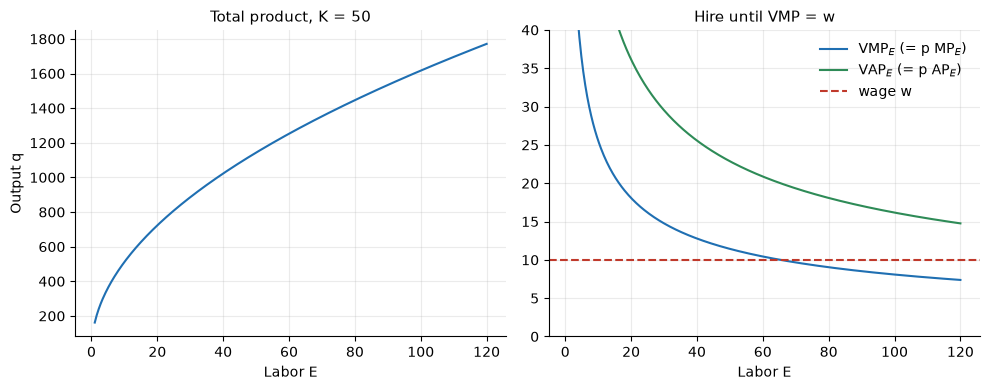

In [2]:
def q_f(E, K, A=D.A, alpha=D.alpha, beta=D.beta):
    return A * K**alpha * E**beta


def E_sr(w, K, p=D.p, A=D.A, alpha=D.alpha, beta=D.beta):
    return (p * A * beta * K**alpha / np.asarray(w, dtype=float)) ** (1 / (1 - beta))


# Numerical check: maximize profit over E with K fixed
K_test = 50.0
for wage in [5.0, 10.0, 20.0]:
    res = minimize_scalar(lambda E: -(D.p * q_f(E, K_test) - wage * E), bounds=(1e-6, 1e4), method="bounded",
                          options={"xatol": 1e-10})
    assert np.isclose(res.x, E_sr(wage, K_test), rtol=1e-4), (res.x, E_sr(wage, K_test))

# Elasticity: finite difference vs closed form
eps_fd = np.log(E_sr(10.5, K_test) / E_sr(9.5, K_test)) / np.log(10.5 / 9.5)
print(f"Short-run elasticity: finite difference {eps_fd:.3f}, closed form {-1 / (1 - D.beta):.3f}")

E_g = np.linspace(1, 120, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(E_g, q_f(E_g, K_test), color=BLUE); axes[0].set_xlabel("Labor E"); axes[0].set_ylabel("Output q")
axes[0].set_title(f"Total product, K = {K_test:.0f}")
axes[1].plot(E_g, D.p * D.beta * q_f(E_g, K_test) / E_g, color=BLUE, label="VMP$_E$ (= p MP$_E$)")
axes[1].plot(E_g, D.p * q_f(E_g, K_test) / E_g, color=GREEN, label="VAP$_E$ (= p AP$_E$)")
axes[1].axhline(D.w, color=RED, ls="--", label="wage w"); axes[1].set_ylim(0, 40)
axes[1].set_xlabel("Labor E"); axes[1].legend(); axes[1].set_title("Hire until VMP = w")
plt.tight_layout(); plt.show()

## 2. Long run: cost minimization and profit maximization (3-3)

**Isoquants and isocosts.** The isoquant $q = AK^{\alpha}E^{\beta}$ has slope $-MP_E/MP_K = -\dfrac{\beta K}{\alpha E}$; the isocost $C = wE + rK$ has slope $-w/r$. Cost minimization for a given $q$ requires tangency (3-13):

$$MRTS = \frac{\beta}{\alpha}\frac{K}{E} = \frac{w}{r} \quad\Longleftrightarrow\quad K = \frac{\alpha w}{\beta r}E .$$

**Profit maximization** (3-15): $w = pMP_E$ and $r = pMP_K$. Their ratio is the cost-minimization condition, so a profit-maximizing firm is cost-minimizing at its chosen $q$.

In [3]:
E_, K_, w_, r_, p_, A_, al, be, q_ = sp.symbols("E K w r p A alpha beta q", positive=True)
qf = A_ * K_**al * E_**be

# Cost minimization at output q: tangency + isoquant
tang = sp.Eq(sp.diff(qf, E_) / sp.diff(qf, K_), w_ / r_)
K_of_E = sp.solve(tang, K_)[0]
E_c = sp.solve(sp.Eq(qf.subs(K_, K_of_E), q_), E_)[0]
E_c = sp.simplify(E_c)
K_c = sp.simplify(K_of_E.subs(E_, E_c))
cost = sp.simplify(w_ * E_c + r_ * K_c)
print("Conditional labor demand E^c(w, r, q):"); display(E_c)
print("Cost function C(w, r, q):"); display(cost)

Conditional labor demand E^c(w, r, q):


(beta**alpha*q*r**alpha/(A*alpha**alpha*w**alpha))**(1/(alpha + beta))

Cost function C(w, r, q):


beta**(alpha/(alpha + beta) - 1)*w**(-alpha/(alpha + beta) + 1)*(q/A)**(1/(alpha + beta))*(r/alpha)**(alpha/(alpha + beta))*(alpha + beta)

In [4]:
E_c_f = sp.lambdify((w_, r_, q_, A_, al, be), E_c, "numpy")
K_c_f = sp.lambdify((w_, r_, q_, A_, al, be), K_c, "numpy")


def cost_min_numeric(w, r, q):
    cons = {"type": "eq", "fun": lambda z: np.log(q_f(z[0], z[1])) - np.log(q)}
    res = minimize(lambda z: w * z[0] + r * z[1], x0=[30, 30], constraints=cons, bounds=[(1e-6, None)] * 2, method="SLSQP",
                   options={"ftol": 1e-12})
    return res.x


q_test = 60.0
E_n, K_n = cost_min_numeric(D.w, D.r, q_test)
E_a, K_a = E_c_f(D.w, D.r, q_test, D.A, D.alpha, D.beta), K_c_f(D.w, D.r, q_test, D.A, D.alpha, D.beta)
print(f"q = {q_test}: numeric (E, K) = ({E_n:.3f}, {K_n:.3f}); closed form = ({E_a:.3f}, {K_a:.3f})")
assert np.allclose([E_n, K_n], [E_a, K_a], rtol=1e-3)

q = 60.0: numeric (E, K) = (1.521, 0.913); closed form = (1.521, 0.913)


**Profit maximization.** The two first-order conditions give the unconditional factor demands. With $a+b<1$ they are

$$E^*(w,r,p) = \Big[\Big(\tfrac{w}{p A \beta}\Big)^{1-\alpha}\Big(\tfrac{r}{p A \alpha}\Big)^{\alpha}\Big]^{-\frac{1}{1-\alpha-\beta}}\ \text{(sympy below)},$$

so the **long-run own-wage elasticity** is $-\dfrac{1-\alpha}{1-\alpha-\beta}$ and the **cross elasticity with the price of capital** is $-\dfrac{\alpha}{1-\alpha-\beta}$.

In [5]:
# The FOCs are linear in logs: ln(p A beta) + alpha lnK + (beta-1) lnE = ln w, etc.
lE, lK, lw, lr, lp = sp.symbols("lnE lnK lnw lnr lnp")
log_foc = [sp.Eq(sp.log(A_ * be) + lp + al * lK + (be - 1) * lE, lw),
           sp.Eq(sp.log(A_ * al) + lp + (al - 1) * lK + be * lE, lr)]
sol_log = sp.solve(log_foc, [lE, lK], dict=True)[0]
lnE_star, lnK_star = sp.simplify(sol_log[lE]), sp.simplify(sol_log[lK])
display(sp.Eq(sp.Symbol("ln E^*"), lnE_star))

# Elasticities of E* w.r.t. w, r, p are the coefficients on ln w, ln r, ln p
elast = {name: sp.simplify(sp.diff(lnE_star, v)) for name, v in [("wage", lw), ("rental rate", lr), ("output price", lp)]}
for name, ex in elast.items():
    print(f"elasticity of E* w.r.t. {name}:", ex)

subs_ = {lw: sp.log(w_), lr: sp.log(r_), lp: sp.log(p_)}
E_star, K_star = sp.exp(lnE_star.subs(subs_)), sp.exp(lnK_star.subs(subs_))

E_star_f = sp.lambdify((w_, r_, p_, A_, al, be), E_star, "numpy")
K_star_f = sp.lambdify((w_, r_, p_, A_, al, be), K_star, "numpy")
args = (D.A, D.alpha, D.beta)
E0_lr = float(E_star_f(D.w, D.r, D.p, *args)); K0_lr = float(K_star_f(D.w, D.r, D.p, *args)); q0_lr = float(q_f(E0_lr, K0_lr))
print(f"\nBaseline long-run optimum: E* = {E0_lr:.2f}, K* = {K0_lr:.2f}, q* = {q0_lr:.2f}, profit = {D.p*q0_lr - D.w*E0_lr - D.r*K0_lr:.2f}")

# Numerical profit maximization
res = minimize(lambda z: -(D.p * q_f(z[0], z[1]) - D.w * z[0] - D.r * z[1]), x0=[10, 10], bounds=[(1e-6, None)] * 2,
               method="L-BFGS-B", options={"ftol": 1e-14, "gtol": 1e-10})
assert np.allclose(res.x, [E0_lr, K0_lr], rtol=1e-3), res.x
# FOCs
assert np.isclose(D.p * D.beta * q0_lr / E0_lr, D.w) and np.isclose(D.p * D.alpha * q0_lr / K0_lr, D.r)
print("First-order conditions and numerical optimum match the closed form.")

Eq(ln E^*, (alpha*lnr - alpha*lnw - lnp + lnw + log(beta**(alpha - 1)/(A*alpha**alpha)))/(alpha + beta - 1))

elasticity of E* w.r.t. wage: (1 - alpha)/(alpha + beta - 1)
elasticity of E* w.r.t. rental rate: alpha/(alpha + beta - 1)
elasticity of E* w.r.t. output price: -1/(alpha + beta - 1)

Baseline long-run optimum: E* = 45.39, K* = 27.23, q* = 907.73, profit = 181.55
First-order conditions and numerical optimum match the closed form.


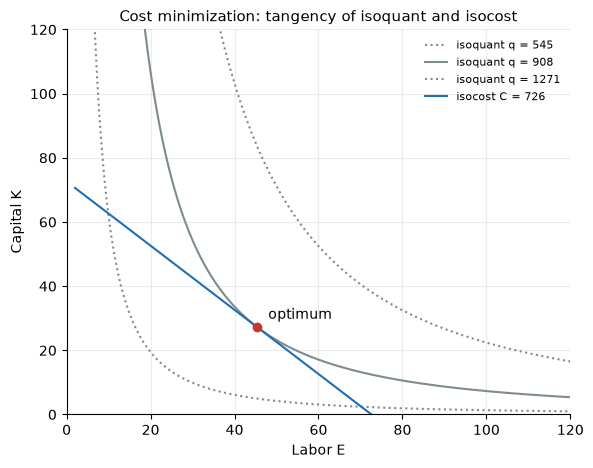

In [6]:
# Diagram: isoquant tangent to the isocost at the long-run optimum (Figure 3-8 style)
Eg = np.linspace(2, 120, 400)
fig, ax = plt.subplots(figsize=(6.5, 5))
for mult, ls in [(0.6, ":"), (1.0, "-"), (1.4, ":")]:
    ax.plot(Eg, isoquant(mult * q0_lr, D.A, D.alpha, D.beta, Eg), color=GREY, ls=ls, label=f"isoquant q = {mult * q0_lr:.0f}")
C_opt = D.w * E0_lr + D.r * K0_lr
ax.plot(Eg, (C_opt - D.w * Eg) / D.r, color=BLUE, label=f"isocost C = {C_opt:.0f}")
ax.plot([E0_lr], [K0_lr], "o", color=RED); ax.annotate("optimum", (E0_lr, K0_lr), textcoords="offset points", xytext=(8, 6))
ax.set_xlim(0, 120); ax.set_ylim(0, 120); ax.set_xlabel("Labor E"); ax.set_ylabel("Capital K"); ax.legend(fontsize=8)
ax.set_title("Cost minimization: tangency of isoquant and isocost")
plt.show()

## 3. The long-run demand curve: substitution and scale effects (3-4)

Raise the wage from $w_0 = 10$ to $w_1 = 15$ (capital price fixed). Three points:

* **A**: old optimum $(E_A, K_A)$ at $(w_0, r)$, output $q_0$.
* **B**: cost-minimizing input mix at the *new* wage for the *old* output $q_0$. A to B is the **substitution effect** (move along the isoquant towards capital).
* **C**: new profit-maximizing choice at $(w_1, r)$. B to C is the **scale effect**: the cost increase raises marginal cost, output falls, and the firm uses less of every input.

Both effects reduce labor, so the long-run demand curve is flatter (more elastic) than the short-run curve with $K$ fixed at $K_A$.

A: E =  45.39  K =  27.23  q = 907.73
B: E =  38.98  K =  35.09  q = 907.73   substitution effect on E = -6.40
C: E =  10.98  K =   9.88  q = 329.40   scale effect on E        = -28.00
Total change in E = -34.41 (-75.8%)
Short-run (K fixed at 27.2) employment at w1 = 20.17  (change -25.21)


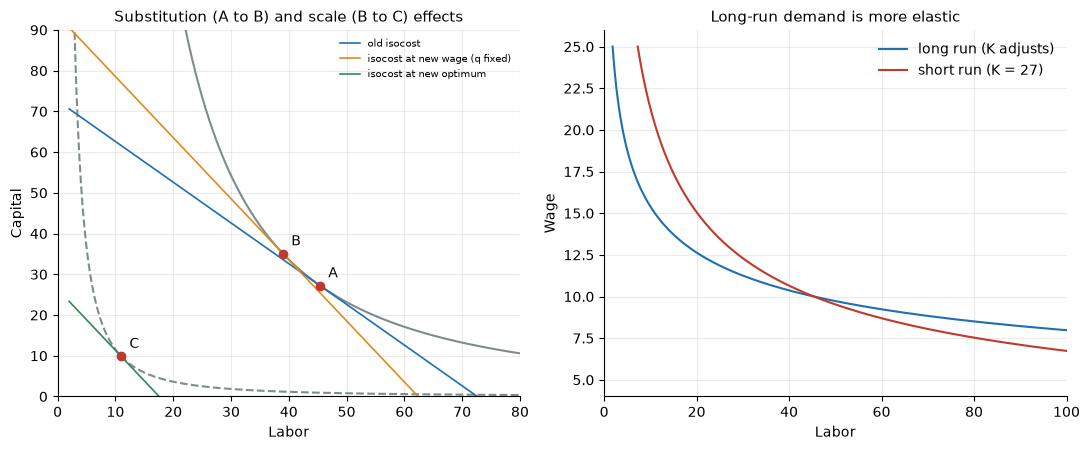

Elasticities at the baseline: SR = -2.0 LR = -3.5
Constant-output (substitution-only) elasticity = -sigma * (1 - s) =  -0.375


In [7]:
w1 = 1.5 * D.w
E_A, K_A, q_A = E0_lr, K0_lr, q0_lr
E_B, K_B = E_c_f(w1, D.r, q_A, *args), K_c_f(w1, D.r, q_A, *args)
E_C, K_C = float(E_star_f(w1, D.r, D.p, *args)), float(K_star_f(w1, D.r, D.p, *args)); q_C = q_f(E_C, K_C)

print(f"A: E = {E_A:6.2f}  K = {K_A:6.2f}  q = {q_A:6.2f}")
print(f"B: E = {E_B:6.2f}  K = {K_B:6.2f}  q = {q_A:6.2f}   substitution effect on E = {E_B - E_A:+.2f}")
print(f"C: E = {E_C:6.2f}  K = {K_C:6.2f}  q = {q_C:6.2f}   scale effect on E        = {E_C - E_B:+.2f}")
print(f"Total change in E = {E_C - E_A:+.2f} ({100 * (E_C / E_A - 1):+.1f}%)")

# Short-run response with K fixed at K_A, for comparison
E_sr1 = float(E_sr(w1, K_A))
print(f"Short-run (K fixed at {K_A:.1f}) employment at w1 = {E_sr1:.2f}  (change {E_sr1 - E_A:+.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
for q_, ls in [(q_A, "-"), (q_C, "--")]:
    ax.plot(Eg, isoquant(q_, D.A, D.alpha, D.beta, Eg), color=GREY, ls=ls)
ax.plot(Eg, (D.w * E_A + D.r * K_A - D.w * Eg) / D.r, color=BLUE, lw=1.2, label="old isocost")
ax.plot(Eg, (w1 * E_B + D.r * K_B - w1 * Eg) / D.r, color=ORANGE, lw=1.2, label="isocost at new wage (q fixed)")
ax.plot(Eg, (w1 * E_C + D.r * K_C - w1 * Eg) / D.r, color=GREEN, lw=1.2, label="isocost at new optimum")
for name, (x, y) in {"A": (E_A, K_A), "B": (E_B, K_B), "C": (E_C, K_C)}.items():
    ax.plot([x], [y], "o", color=RED); ax.annotate(name, (x, y), textcoords="offset points", xytext=(6, 6))
ax.set_xlim(0, 80); ax.set_ylim(0, 90); ax.set_xlabel("Labor"); ax.set_ylabel("Capital"); ax.legend(fontsize=7)
ax.set_title("Substitution (A to B) and scale (B to C) effects")

wg = np.linspace(5, 25, 100)
ax = axes[1]
ax.plot(E_star_f(wg, D.r, D.p, *args), wg, color=BLUE, label="long run (K adjusts)")
ax.plot(E_sr(wg, K_A), wg, color=RED, label=f"short run (K = {K_A:.0f})")
ax.set_xlim(0, 100); ax.set_xlabel("Labor"); ax.set_ylabel("Wage"); ax.legend()
ax.set_title("Long-run demand is more elastic")
plt.tight_layout(); plt.show()

print("Elasticities at the baseline: SR =", round(-1 / (1 - D.beta), 2),
      "LR =", round(-(1 - D.alpha) / (1 - D.alpha - D.beta), 2))
print("Constant-output (substitution-only) elasticity = -sigma * (1 - s) = ", round(-1 * D.alpha / (D.alpha + D.beta), 3))

The firm-level long-run elasticity here is large because returns to scale are close to 1, so the scale effect is large. The substitution-only elasticity $-\sigma(1-s) = -\alpha/(\alpha+\beta) \approx -0.375$ is much closer to the empirical range for the *market* labor demand elasticity (roughly $-0.15$ to $-0.75$) that Borjas reports.

## 4. The elasticity of substitution (3-5)

$$\sigma = \frac{d\ln(K/E)}{d\ln(MRTS)} = \frac{\%\Delta (K/E)}{\%\Delta (w/r)} \quad\text{(along an isoquant)} .$$

Cobb-Douglas has $\sigma = 1$. The CES function $q = A\,[\,a K^{\rho} + (1-a)E^{\rho}\,]^{1/\rho}$, $\sigma = 1/(1-\rho)$, nests the Leontief case ($\sigma\to 0$, right-angle isoquants) and perfect substitutes ($\sigma \to\infty$, straight isoquants). The figure uses the *normalized* CES form so that all isoquants pass through the same point with the same slope.

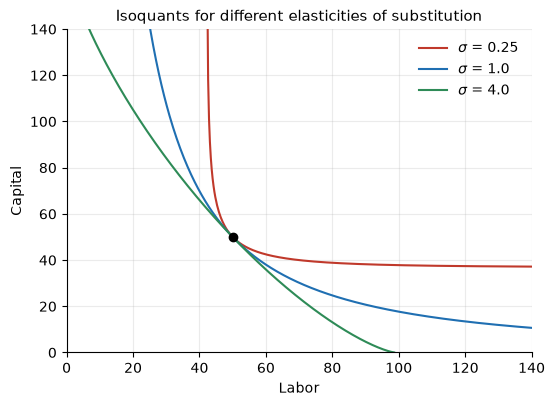

sigma=0.5: estimated 0.500
sigma=2.0: estimated 2.000


In [8]:
def ces_isoquant(E, sigma, a=0.4, E0=50.0, K0=50.0):
    # normalized CES isoquant through (E0, K0) with common slope there
    if np.isclose(sigma, 1.0):
        return K0 * (E / E0) ** (-(1 - a) / a)
    rho = 1 - 1 / sigma
    inner = (1 - (1 - a) * (E / E0) ** rho) / a
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(inner > 0, K0 * np.abs(inner) ** (1 / rho), np.nan)


fig, ax = plt.subplots()
Eg2 = np.linspace(5, 140, 500)
for s, c in [(0.25, RED), (1.0, BLUE), (4.0, GREEN)]:
    ax.plot(Eg2, ces_isoquant(Eg2, s), color=c, label=fr"$\sigma$ = {s}")
ax.plot([50], [50], "ko"); ax.set_xlim(0, 140); ax.set_ylim(0, 140)
ax.set_xlabel("Labor"); ax.set_ylabel("Capital"); ax.legend(); ax.set_title("Isoquants for different elasticities of substitution")
plt.show()

# Check: sigma = dln(K/E) / dln(w/r) for the CES cost-minimizing mix (numeric)
def sigma_numeric(sigma, a=0.4, E0=50.0, K0=50.0, wr0=1.0):
    def ratio(wr):
        # choose E on the isoquant where MRTS = wr; MRTS = (1-a)/a * (K/E)^(1-rho) * (E0/K0)^rho...
        rho = 1 - 1 / sigma
        f = lambda E: abs(((1 - a) / a) * (K0 / E0) ** (-rho) * (ces_isoquant(E, sigma) / E) ** (1 - rho) - wr)
        E = minimize_scalar(f, bounds=(10, 140), method="bounded", options={"xatol": 1e-12}).x
        return ces_isoquant(E, sigma) / E
    h = 1e-3
    return np.log(ratio(wr0 * (1 + h)) / ratio(wr0 / (1 + h))) / np.log((1 + h) / (1 / (1 + h)))

for s in [0.5, 2.0]:
    print(f"sigma={s}: estimated {sigma_numeric(s):.3f}")
    assert abs(sigma_numeric(s) - s) < 0.01

## 5. Rules of derived demand and many inputs (3-6, 3-7)

Hicks-Marshall: the own-wage labor demand elasticity of an industry with competitive product and input markets is

$$\delta = -\big[(1-s)\,\sigma + s\,\eta\big],$$

so demand is more elastic when (1) labor is easy to substitute ($\sigma$ large), (2) product demand is elastic ($\eta$ large), (3) labor is a large cost share ($s$ large, for $\eta>\sigma$), and, with a fourth rule not tested here, (4) the supply of the other inputs is elastic.

The code verifies the formula numerically for a constant-returns CES industry: unit cost $c(w,r)$, product demand $Q = B c^{-\eta}$, and labor demand $E = Q\,\partial c/\partial w$ (Shephard's lemma).

In [9]:
def unit_cost_ces(w, r, sigma, a=0.4, A=1.0):
    if np.isclose(sigma, 1.0):
        return (1 / A) * (w / (1 - a)) ** (1 - a) * (r / a) ** a
    return (1 / A) * ((1 - a) ** sigma * w ** (1 - sigma) + a**sigma * r ** (1 - sigma)) ** (1 / (1 - sigma))


def industry_labor_demand(w, r, sigma, eta, B=100.0):
    h = 1e-6
    c = unit_cost_ces(w, r, sigma)
    c_w = (unit_cost_ces(w * (1 + h), r, sigma) - unit_cost_ces(w * (1 - h), r, sigma)) / (2 * h * w)  # Shephard
    return B * c ** (-eta) * c_w, c, c_w


rows = []
for sigma in [0.5, 1.0, 3.0]:
    for eta in [0.5, 1.5]:
        w_, r_0 = 10.0, 10.0
        E, c, c_w = industry_labor_demand(w_, r_0, sigma, eta)
        s_share = w_ * c_w / c
        h = 1e-4
        eps = np.log(industry_labor_demand(w_ * (1 + h), r_0, sigma, eta)[0] / industry_labor_demand(w_ * (1 - h), r_0, sigma, eta)[0]) / np.log((1 + h) / (1 - h))
        hm = -((1 - s_share) * sigma + s_share * eta)
        rows.append((sigma, eta, s_share, eps, hm))
        assert np.isclose(eps, hm, atol=1e-3), (sigma, eta, eps, hm)

print(f"{'sigma':>6} {'eta':>5} {'s':>6} {'numeric':>9} {'Hicks-Marshall':>15}")
for sg, et, s_, e_, h_ in rows:
    print(f"{sg:6.1f} {et:5.1f} {s_:6.3f} {e_:9.3f} {h_:15.3f}")

 sigma   eta      s   numeric  Hicks-Marshall
   0.5   0.5  0.551    -0.500          -0.500
   0.5   1.5  0.551    -1.051          -1.051
   1.0   0.5  0.600    -0.700          -0.700
   1.0   1.5  0.600    -1.300          -1.300
   3.0   0.5  0.771    -1.071          -1.071
   3.0   1.5  0.771    -1.843          -1.843


**Many inputs (3-7).** For two inputs with the Cobb-Douglas technology above, the sign of the cross-price elasticity depends on whether output is held constant:

* output fixed ($\partial \ln E^c/\partial \ln r$): $+\dfrac{\alpha}{\alpha+\beta}$, so labor and capital are **net (Hicks-Allen) substitutes**;
* output free ($\partial \ln E^*/\partial \ln r$): $-\dfrac{\alpha}{1-\alpha-\beta}$, so the scale effect dominates and they are **gross complements**.

The sympy output in section 2 gives the second number directly; the check below computes both by finite differences.

In [10]:
h = 1e-4
gross = np.log(E_star_f(D.w, D.r * (1 + h), D.p, *args) / E_star_f(D.w, D.r * (1 - h), D.p, *args)) / np.log((1 + h) / (1 - h))
net = np.log(E_c_f(D.w, D.r * (1 + h), q_A, *args) / E_c_f(D.w, D.r * (1 - h), q_A, *args)) / np.log((1 + h) / (1 - h))
print(f"Gross cross elasticity (output free):  {gross:+.3f}   formula {-D.alpha / (1 - D.alpha - D.beta):+.3f}")
print(f"Net cross elasticity (output fixed):   {net:+.3f}   formula {D.alpha / (D.alpha + D.beta):+.3f}")
assert np.isclose(gross, -D.alpha / (1 - D.alpha - D.beta), atol=1e-3) and np.isclose(net, D.alpha / (D.alpha + D.beta), atol=1e-3)

Gross cross elasticity (output free):  -1.500   formula -1.500
Net cross elasticity (output fixed):   +0.375   formula +0.375


## 6. Minimum wage in the competitive model (3-10)

A minimum wage $w_{min}$ above the equilibrium wage $w^*$ moves employment *along the demand curve*, $\%\Delta E = \delta\,\%\Delta w$. With a constant-elasticity supply curve, workers supplied at $w_{min}$ exceed those demanded, creating unemployment $S(w_{min}) - D(w_{min})$.

**Covered and uncovered sectors.** If only a fraction of jobs is covered, displaced workers move to the uncovered sector, which pushes down wages there. With total labor fixed at $N$ and constant-elasticity demands $E_i = E_{i0}(w/w_0)^{\delta}$, the uncovered wage solves $E_u(w_u) = N - E_c(w_{min})$.

Minimum wage 22.0 (+10%): employment 93.1 (-6.9%), labor supplied 104.9, unemployment 11.8


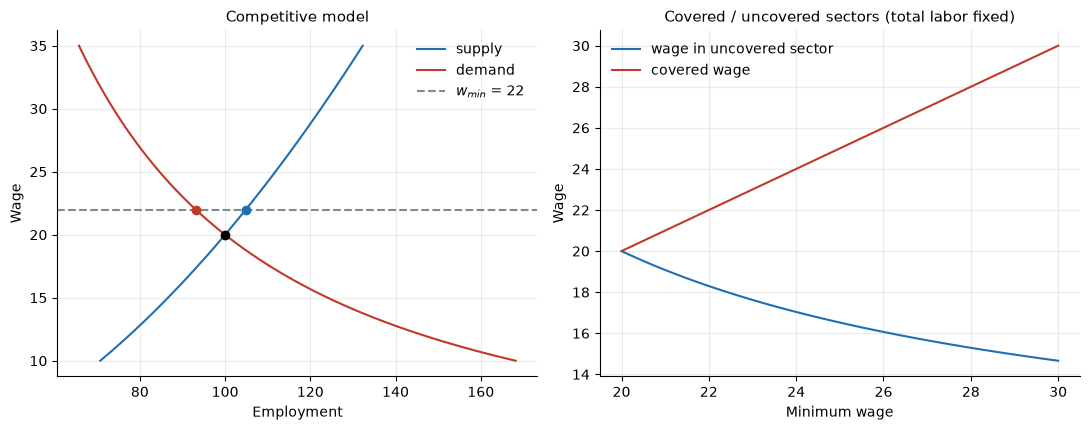

With a 10% minimum wage, the uncovered wage falls to 18.27 (from 20.0).


In [11]:
from scipy.optimize import brentq

M = market
S_f, S_inv = curve_from_elasticity(M.w0, M.E0, M.eps_S)
D_f, D_inv = curve_from_elasticity(M.w0, M.E0, M.delta)
w_min = 1.10 * M.w0

E_dem = float(D_f(w_min)); E_sup = float(S_f(w_min))
print(f"Minimum wage {w_min:.1f} (+10%): employment {E_dem:.1f} ({100 * (E_dem / M.E0 - 1):+.1f}%), "
      f"labor supplied {E_sup:.1f}, unemployment {E_sup - E_dem:.1f}")

wg = np.linspace(10, 35, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot(S_f(wg), wg, color=BLUE, label="supply"); ax.plot(D_f(wg), wg, color=RED, label="demand")
ax.axhline(w_min, color=GREY, ls="--", label=f"$w_{{min}}$ = {w_min:.0f}")
ax.plot([M.E0], [M.w0], "ko"); ax.plot([E_dem], [w_min], "o", color=RED); ax.plot([E_sup], [w_min], "o", color=BLUE)
ax.set_xlabel("Employment"); ax.set_ylabel("Wage"); ax.legend(); ax.set_title("Competitive model")

# Two sectors, each with half of the labor force and the same demand elasticity
N = M.E0
Ec = lambda w: 0.5 * M.E0 * (w / M.w0) ** M.delta
Eu = lambda w: 0.5 * M.E0 * (w / M.w0) ** M.delta
mins = np.linspace(M.w0, 1.5 * M.w0, 60)
w_unc = np.array([brentq(lambda w: Eu(w) - (N - Ec(m)), 1.0, 200.0) for m in mins])
ax = axes[1]
ax.plot(mins, w_unc, color=BLUE, label="wage in uncovered sector")
ax.plot(mins, mins, color=RED, label="covered wage"); ax.set_xlabel("Minimum wage"); ax.set_ylabel("Wage")
ax.legend(); ax.set_title("Covered / uncovered sectors (total labor fixed)")
plt.tight_layout(); plt.show()
i = np.argmin(abs(mins - w_min))
print(f"With a 10% minimum wage, the uncovered wage falls to {w_unc[i]:.2f} (from {M.w0}).")
assert np.isclose(float(Eu(w_unc[i]) + Ec(mins[i])), N)

## Check list

* Short run: $VMP_E = w$; $\delta^{SR} = -1/(1-\beta) = -2$ (closed form, finite difference and numerical optimum agree).
* Long run: closed-form conditional demand and factor demands match `scipy` cost minimization and profit maximization; $\delta^{LR} = -(1-\alpha)/(1-\alpha-\beta) = -3.5$, more elastic than the short run.
* The decomposition A to B to C splits the wage effect into substitution and scale parts.
* Hicks-Marshall: $\delta = -[(1-s)\sigma + s\eta]$ verified numerically for CES industries.
* Labor and capital are net substitutes but gross complements under Cobb-Douglas with decreasing returns.